In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Official UCI file (no header row): data_banknote_authentication.txt
cols = ["Variance", "Skewness", "Curtosis", "Entropy", "Class"]
df = pd.read_csv("data_banknote_authentication.txt", header=None, names=cols)
print("Loaded:", df.shape)

Loaded: (1372, 5)


In [3]:
LABEL_NAMES = {0: "Genuine (assumed)", 1: "Forged (assumed)"}   # working assumption - verify
POSITIVE_CLASS = 1

In [5]:
print("First ten records:")
df.head(10)

First ten records:


,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.80730,-0.44699,0
1,4.54590,8.1674,-2.45860,-1.46210,0
2,3.86600,-2.6383,1.92420,0.10645,0
3,3.45660,9.5228,-4.01120,-3.59440,0
4,0.32924,-4.4552,4.57180,-0.98880,0
5,4.36840,9.6718,-3.96060,-3.16250,0
6,3.59120,3.0129,0.72888,0.56421,0
7,2.09220,-6.8100,8.46360,-0.60216,0
8,3.20320,5.7588,-0.75345,-0.61251,0
9,1.53560,9.1772,-2.27180,-0.73535,0


In [7]:
print("Rows, columns:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows (extra copies):", df.duplicated().sum())
print("Rows involved in any duplication:", df.duplicated(keep=False).sum())
print("Class of duplicated rows:\n", df[df.duplicated(keep=False)]["Class"].value_counts())

Rows, columns: (1372, 5)

Data types:
 Variance    float64
Skewness    float64
Curtosis    float64
Entropy     float64
Class         int64
dtype: object

Missing values per column:
 Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64

Duplicate rows (extra copies): 24
Rows involved in any duplication: 35
Class of duplicated rows:
 Class
0    35
Name: count, dtype: int64


In [9]:
df.describe().round(3)

,Variance,Skewness,Curtosis,Entropy,Class
count,1372.000,1372.000,1372.000,1372.000,1372.000
mean,0.434,1.922,1.398,-1.192,0.445
std,2.843,5.869,4.310,2.101,0.497
min,-7.042,-13.773,-5.286,-8.548,0.000
25%,-1.773,-1.708,-1.575,-2.413,0.000
50%,0.496,2.320,0.617,-0.587,0.000
75%,2.821,6.815,3.179,0.395,1.000
max,6.825,12.952,17.927,2.450,1.000


In [11]:
counts = df["Class"].value_counts().sort_index()
pct = (df["Class"].value_counts(normalize=True).sort_index() * 100).round(2)
print(pd.DataFrame({"count": counts, "percent": pct}))

       count  percent
Class                
0        762    55.54
1        610    44.46


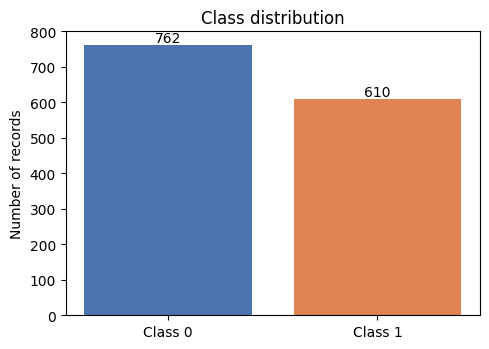

In [13]:
fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(["Class 0", "Class 1"], counts.values, color=["#4C72B0", "#DD8452"])
ax.bar_label(bars)
ax.set_ylabel("Number of records"); ax.set_title("Class distribution")
plt.tight_layout(); plt.savefig("fig_class_distribution.png", dpi=150); plt.show()

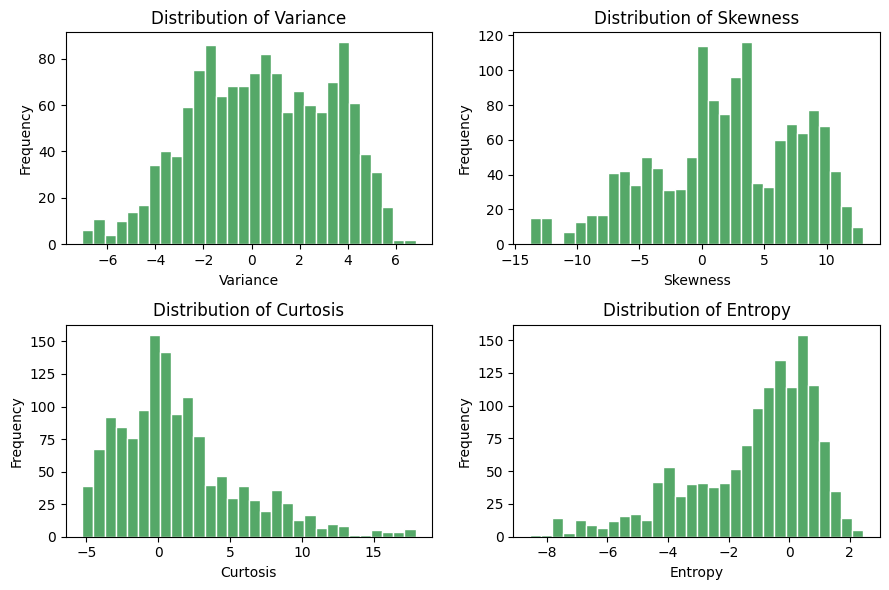

In [15]:
features = cols[:4]
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for a, f in zip(axes.ravel(), features):
    a.hist(df[f], bins=30, color="#55A868", edgecolor="white")
    a.set_title(f"Distribution of {f}"); a.set_xlabel(f); a.set_ylabel("Frequency")
plt.tight_layout(); plt.savefig("fig_histograms.png", dpi=150); plt.show()

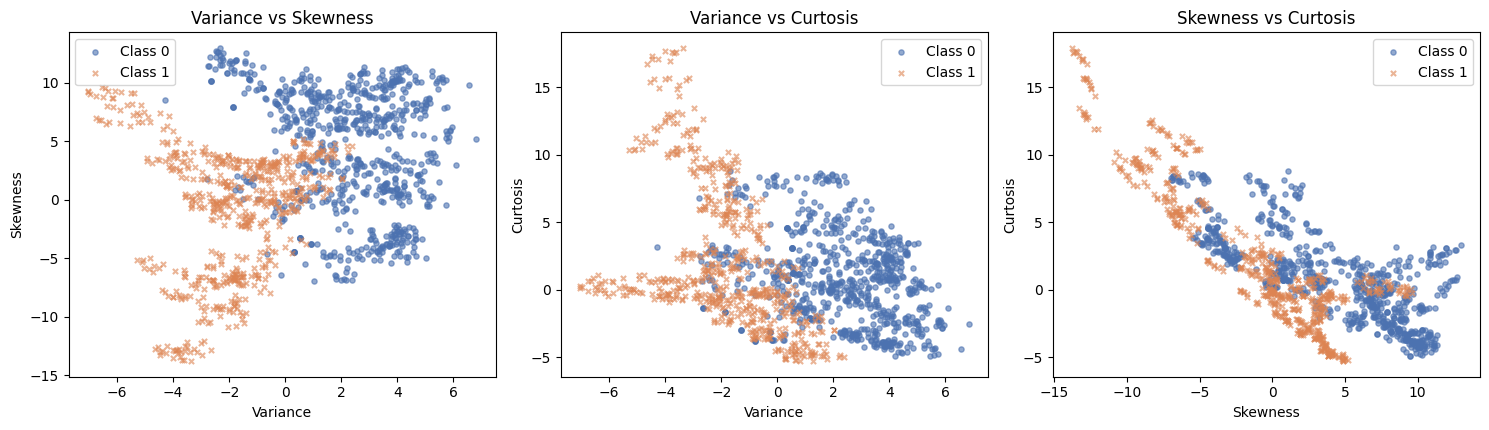

In [17]:
pairs = [("Variance", "Skewness"), ("Variance", "Curtosis"), ("Skewness", "Curtosis")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for a, (fx, fy) in zip(axes, pairs):
    for c, colr, mk in [(0, "#4C72B0", "o"), (1, "#DD8452", "x")]:
        s = df[df["Class"] == c]
        a.scatter(s[fx], s[fy], s=14, alpha=0.6, c=colr, marker=mk, label=f"Class {c}")
    a.set_xlabel(fx); a.set_ylabel(fy); a.set_title(f"{fx} vs {fy}"); a.legend()
plt.tight_layout(); plt.savefig("fig_scatter.png", dpi=150); plt.show()

In [19]:
X = df[features]
y = df["Class"]
print("Number of input features:", X.shape[1])
print("Shape of X:", X.shape, "| Shape of y:", y.shape)

Number of input features: 4
Shape of X: (1372, 4) | Shape of y: (1372,)


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print("Training records:", len(X_train), "| Testing records:", len(X_test))
print("Train class counts:", y_train.value_counts().sort_index().to_dict())
print("Test class counts: ", y_test.value_counts().sort_index().to_dict())
print("Train Class-1 share: %.4f | Test Class-1 share: %.4f" % (y_train.mean(), y_test.mean()))

Training records: 1097 | Testing records: 275
Train class counts: {0: 609, 1: 488}
Test class counts:  {0: 153, 1: 122}
Train Class-1 share: 0.4448 | Test Class-1 share: 0.4436


In [23]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit ONLY on training data
X_test_s = scaler.transform(X_test)         # reuse training mean/std on test data
print("Training means used by scaler:", scaler.mean_.round(3))
print("Training std used by scaler:  ", scaler.scale_.round(3))

Training means used by scaler: [ 0.463  1.873  1.409 -1.214]
Training std used by scaler:   [2.839 5.905 4.355 2.111]


In [25]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)
print("Training completed. Settings:", model.get_params())
print("Converged in iterations:", int(model.n_iter_[0]))
print("Coefficients (scaled features):", {f: round(float(c), 3) for f, c in zip(features, model.coef_[0])})
print("Intercept:", round(float(model.intercept_[0]), 3))

Training completed. Settings: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Converged in iterations: 11
Coefficients (scaled features): {'Variance': -4.666, 'Skewness': -4.807, 'Curtosis': -4.399, 'Entropy': 0.258}
Intercept: -1.4


In [27]:
y_pred = model.predict(X_test_s)
y_proba = model.predict_proba(X_test_s)          # columns: [P(Class 0), P(Class 1)]
compare = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred,
                        "P(Class 0)": y_proba[:, 0].round(4), "P(Class 1)": y_proba[:, 1].round(4)})
compare["Correct"] = compare["Actual"] == compare["Predicted"]
print("Actual vs predicted (first 15 test records):")
compare.head(15)

Actual vs predicted (first 15 test records):


,Actual,Predicted,P(Class 0),P(Class 1),Correct
0,0,0,0.9996,0.0004,True
1,1,1,0.0336,0.9664,True
2,0,0,0.7556,0.2444,True
3,1,1,0.0356,0.9644,True
4,1,1,0.0070,0.9930,True
5,1,1,0.2600,0.7400,True
6,0,0,0.9993,0.0007,True
7,0,0,0.9998,0.0002,True
8,0,0,0.9967,0.0033,True
9,1,1,0.0779,0.9221,True


In [29]:
print("Probability results (first 10 test records):")
compare.head(10)[["Actual", "Predicted", "P(Class 0)", "P(Class 1)"]]

Probability results (first 10 test records):


,Actual,Predicted,P(Class 0),P(Class 1)
0,0,0,0.9996,0.0004
1,1,1,0.0336,0.9664
2,0,0,0.7556,0.2444
3,1,1,0.0356,0.9644
4,1,1,0.0070,0.9930
5,1,1,0.2600,0.7400
6,0,0,0.9993,0.0007
7,0,0,0.9998,0.0002
8,0,0,0.9967,0.0033
9,1,1,0.0779,0.9221


In [31]:
print("Incorrect predictions:", (~compare["Correct"]).sum(), "of", len(compare))
compare[~compare["Correct"]]

Incorrect predictions: 8 of 275


,Actual,Predicted,P(Class 0),P(Class 1),Correct
70,0,1,0.3925,0.6075,False
114,0,1,0.3089,0.6911,False
121,0,1,0.4459,0.5541,False
125,0,1,0.4459,0.5541,False
140,0,1,0.3662,0.6338,False
162,0,1,0.2651,0.7349,False
221,0,1,0.3089,0.6911,False
223,0,1,0.3089,0.6911,False


In [33]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label=1)
rec = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)
print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision (Class 1): {prec:.4f}")
print(f"Recall    (Class 1): {rec:.4f}")
print(f"F1-score  (Class 1): {f1:.4f}")
print()
print(classification_report(y_test, y_pred, digits=4))

Accuracy : 0.9709 (97.09%)
Precision (Class 1): 0.9385
Recall    (Class 1): 1.0000
F1-score  (Class 1): 0.9683

              precision    recall  f1-score   support

           0     1.0000    0.9477    0.9732       153
           1     0.9385    1.0000    0.9683       122

    accuracy                         0.9709       275
   macro avg     0.9692    0.9739    0.9707       275
weighted avg     0.9727    0.9709    0.9710       275



Confusion matrix (rows = actual, cols = predicted, order [0, 1]):
 [[145   8]
 [  0 122]]
TN = 145, FP = 8, FN = 0, TP = 122


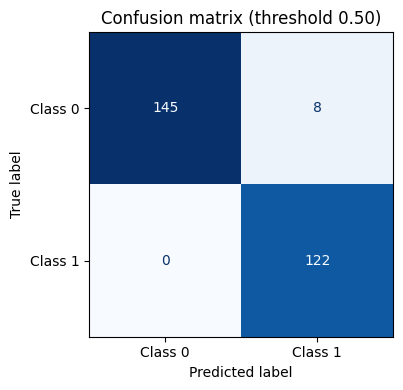

In [35]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix (rows = actual, cols = predicted, order [0, 1]):\n", cm)
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(cm, display_labels=["Class 0", "Class 1"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (threshold 0.50)")
plt.tight_layout(); plt.savefig("fig_confusion_matrix.png", dpi=150); plt.show()

In [37]:
p1 = y_proba[:, 1]
rows, cms = [], {}
for t in (0.30, 0.50, 0.70):
    pred_t = (p1 >= t).astype(int)
    cm_t = confusion_matrix(y_test, pred_t, labels=[0, 1]); cms[t] = cm_t
    tn_, fp_, fn_, tp_ = cm_t.ravel()
    rows.append({"Threshold": t, "Predicted Class 1": int(pred_t.sum()),
                 "Accuracy": accuracy_score(y_test, pred_t),
                 "Precision": precision_score(y_test, pred_t, zero_division=0),
                 "Recall": recall_score(y_test, pred_t),
                 "F1": f1_score(y_test, pred_t), "TN": tn_, "FP": fp_, "FN": fn_, "TP": tp_})
thr_table = pd.DataFrame(rows).round(4)
thr_table

,Threshold,Predicted Class 1,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,0.3,130,0.9709,0.9385,1.0,0.9683,145,8,0,122
1,0.5,130,0.9709,0.9385,1.0,0.9683,145,8,0,122
2,0.7,123,0.9964,0.9919,1.0,0.9959,152,1,0,122


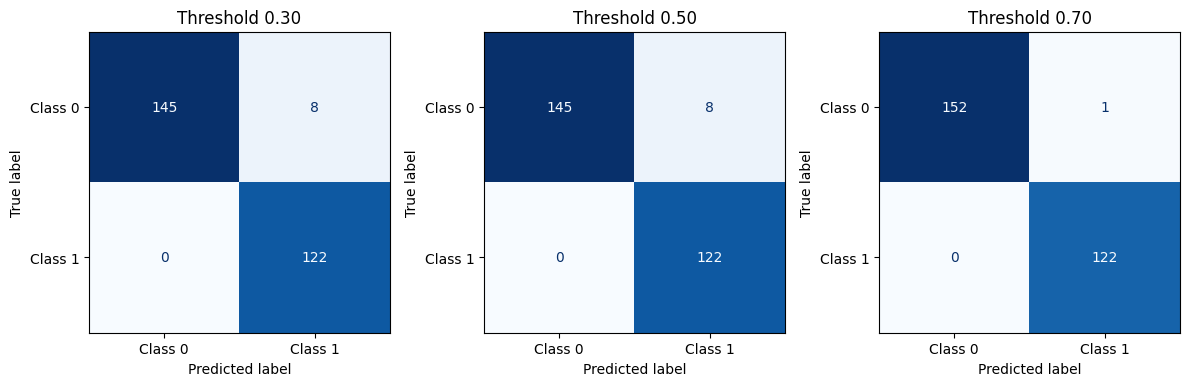

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for a, t in zip(axes, (0.30, 0.50, 0.70)):
    ConfusionMatrixDisplay(cms[t], display_labels=["Class 0", "Class 1"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"Threshold {t:.2f}")
plt.tight_layout(); plt.savefig("fig_threshold_confusion.png", dpi=150); plt.show()

In [41]:
print("Test records with P(Class 1) between 0.30 and 0.50:", int(((p1 >= 0.30) & (p1 < 0.50)).sum()))
print("Test records with P(Class 1) between 0.50 and 0.70:", int(((p1 >= 0.50) & (p1 < 0.70)).sum()))

Test records with P(Class 1) between 0.30 and 0.50: 0
Test records with P(Class 1) between 0.50 and 0.70: 7


In [43]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))   # scaler refit inside each fold
cv = cross_val_score(pipe, X, y, cv=skf, scoring="accuracy")
print("CV accuracy per fold:", cv.round(4))
print(f"Mean = {cv.mean():.4f}, Std = {cv.std():.4f}")

CV accuracy per fold: [0.9818 0.9782 0.9781 0.9745 0.9927]
Mean = 0.9811, Std = 0.0063


In [45]:
tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
yt = tree.predict(X_test)
comp = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, yt)],
    "Precision": [precision_score(y_test, y_pred), precision_score(y_test, yt)],
    "Recall": [recall_score(y_test, y_pred), recall_score(y_test, yt)],
    "F1": [f1_score(y_test, y_pred), f1_score(y_test, yt)]}).round(4)
comp

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.9709,0.9385,1.0,0.9683
1,Decision Tree,0.9927,0.9839,1.0,0.9919


In [47]:
rows = []
for C in (0.001, 0.01, 0.1, 1, 10, 100):
    m = LogisticRegression(C=C, max_iter=1000).fit(X_train_s, y_train)
    pr = m.predict(X_test_s)
    rows.append({"C": C, "Accuracy": accuracy_score(y_test, pr), "Recall": recall_score(y_test, pr),
                 "Precision": precision_score(y_test, pr), "F1": f1_score(y_test, pr)})
pd.DataFrame(rows).round(4)

,C,Accuracy,Recall,Precision,F1
0,0.001,0.8582,0.6967,0.9770,0.8134
1,0.010,0.9382,0.9180,0.9412,0.9295
2,0.100,0.9709,1.0000,0.9385,0.9683
3,1.000,0.9709,1.0000,0.9385,0.9683
4,10.000,0.9855,1.0000,0.9683,0.9839
5,100.000,0.9855,1.0000,0.9683,0.9839
